In [1]:

# CodeAlpha Task 4 – Sentiment Analysis

## Project Overview

This project focuses on analyzing text reviews and classifying them into positive and negative sentiments using Natural Language Processing (NLP) and Machine Learning.

### Objectives
- Analyze customer reviews.
- Clean and preprocess text data.
- Perform sentiment classification.
- Train a Logistic Regression model.
- Evaluate model performance.
- Compare Machine Learning results with VADER sentiment analysis.

### Dataset
The project uses the UCI Sentiment Labelled Sentences dataset, containing 3,000 reviews from Amazon, IMDb, and Yelp.

**Author:** Adhithya  
**Internship:** CodeAlpha – Data Analytics / Machine Learning Task 4


SyntaxError: invalid character '–' (U+2013) (931999964.py, line 19)


# CodeAlpha Task 4 – Sentiment Analysis

## Project Overview

This project focuses on analyzing text reviews and classifying them into positive and negative sentiments using Natural Language Processing (NLP) and Machine Learning.

### Objectives
- Analyze customer reviews.
- Clean and preprocess text data.
- Perform sentiment classification.
- Train a Logistic Regression model.
- Evaluate model performance.
- Compare Machine Learning results with VADER sentiment analysis.

### Dataset
The project uses the UCI Sentiment Labelled Sentences dataset, containing 3,000 reviews from Amazon, IMDb, and Yelp.

**Author:** Adhithya

**Internship:** CodeAlpha – Data Analytics / Machine Learning Task 4


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from wordcloud import WordCloud

%matplotlib inline

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('vader_lexicon')

print("NLTK resources downloaded successfully!")

NLTK resources downloaded successfully!


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\atcha\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\atcha\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\atcha\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\atcha\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [4]:
dataset_path = "../dataset/combined_sentiment_dataset.csv"

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (3000, 3)


,review,label,source
0,So there is no way for me to plug it in here i...,0,Amazon
1,"Good case, Excellent value.",1,Amazon
2,Great for the jawbone.,1,Amazon
3,Tied to charger for conversations lasting more...,0,Amazon
4,The mic is great.,1,Amazon


In [5]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nSentiment Distribution:")
print(df['sentiment'].value_counts())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   review  3000 non-null   str  
 1   label   3000 non-null   int64
 2   source  3000 non-null   str  
dtypes: int64(1), str(2)
memory usage: 70.4 KB

Missing Values:
review    0
label     0
source    0
dtype: int64

Column Names:
['review', 'label', 'source']

Sentiment Distribution:


KeyError: 'sentiment'

In [6]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nSentiment Distribution:")
print(df['label'].value_counts())

print("\nSource Distribution:")
print(df['source'].value_counts())

print("\nSentiment Labels:")
print("0 = Negative")
print("1 = Positive")

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   review  3000 non-null   str  
 1   label   3000 non-null   int64
 2   source  3000 non-null   str  
dtypes: int64(1), str(2)
memory usage: 70.4 KB

Missing Values:
review    0
label     0
source    0
dtype: int64

Column Names:
['review', 'label', 'source']

Sentiment Distribution:
label
0    1500
1    1500
Name: count, dtype: int64

Source Distribution:
source
Amazon    1000
IMDb      1000
Yelp      1000
Name: count, dtype: int64

Sentiment Labels:
0 = Negative
1 = Positive


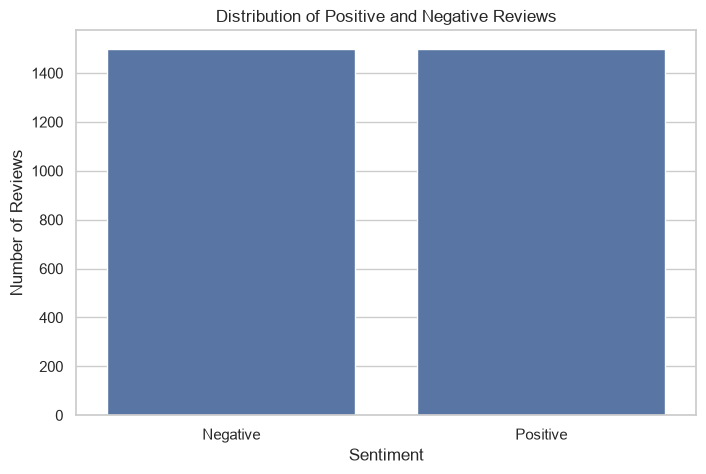

In [7]:
# Sentiment distribution

sentiment_counts = df['label'].value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(
    x=['Negative', 'Positive'],
    y=sentiment_counts.values
)

plt.title("Distribution of Positive and Negative Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.savefig("../visualizations/sentiment_distribution.png",
            bbox_inches="tight")
plt.show()

        Negative  Positive
source                    
Amazon       500       500
IMDb         500       500
Yelp         500       500


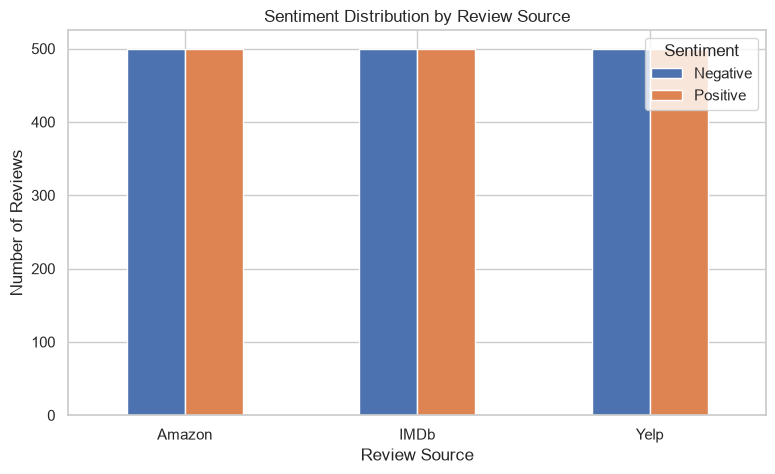

In [8]:
source_sentiment = pd.crosstab(
    df['source'],
    df['label']
)

source_sentiment.columns = ['Negative', 'Positive']

print(source_sentiment)

source_sentiment.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title("Sentiment Distribution by Review Source")
plt.xlabel("Review Source")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.legend(title="Sentiment")

plt.savefig("../visualizations/source_sentiment.png",
            bbox_inches="tight")
plt.show()


## Exploratory Data Analysis

The dataset contains 3,000 customer reviews collected from Amazon, IMDb, and Yelp.

The dataset has three columns:
- Review: Original customer review.
- Label: Sentiment classification (0 = Negative, 1 = Positive).
- Source: Platform from which the review was collected.

The dataset contains no missing values and has a balanced distribution of positive and negative reviews.



## Text Preprocessing

Text preprocessing is an important step in Natural Language Processing (NLP). It transforms raw customer reviews into clean text suitable for machine learning.

The preprocessing operations include:

1. Converting text to lowercase.
2. Removing URLs and HTML tags.
3. Removing special characters and numbers.
4. Removing unnecessary stopwords.
5. Applying lemmatization.
6. Preserving important negation words such as "not", "no", and "never".


In [9]:
stop_words = set(stopwords.words('english'))

# Preserve important negation words
negation_words = {'not', 'no', 'nor', 'never', 'neither'}
stop_words = stop_words - negation_words

lemmatizer = WordNetLemmatizer()

print("NLP preprocessing tools initialized!")

NLP preprocessing tools initialized!


In [10]:
def clean_text(text):
    # Convert to lowercase
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove special characters and numbers
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Tokenization
    words = text.split()

    # Remove stopwords and apply lemmatization
    cleaned_words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return ' '.join(cleaned_words)


print("Text cleaning function created successfully!")

Text cleaning function created successfully!


In [11]:
df['cleaned_review'] = df['review'].apply(clean_text)

print("Text preprocessing completed!")

display(df[['review', 'cleaned_review', 'label']].head(10))

Text preprocessing completed!


,review,cleaned_review,label
0,So there is no way for me to plug it in here i...,no way plug u unless go converter,0
1,"Good case, Excellent value.",good case excellent value,1
2,Great for the jawbone.,great jawbone,1
3,Tied to charger for conversations lasting more...,tied charger conversation lasting minutesmajor...,0
4,The mic is great.,mic great,1
5,I have to jiggle the plug to get it to line up...,jiggle plug get line right get decent volume,0
6,If you have several dozen or several hundred c...,several dozen several hundred contact imagine ...,0
7,If you are Razr owner...you must have this!,razr owneryou must,1
8,"Needless to say, I wasted my money.",needless say wasted money,0
9,What a waste of money and time!.,waste money time,0


In [12]:
sample_review = df['review'].iloc[0]
cleaned_sample = df['cleaned_review'].iloc[0]

print("Original Review:")
print(sample_review)

print("\nCleaned Review:")
print(cleaned_sample)

Original Review:
So there is no way for me to plug it in here in the US unless I go by a converter.

Cleaned Review:
no way plug u unless go converter



## TF-IDF Vectorization

TF-IDF (Term Frequency–Inverse Document Frequency) converts text into numerical features that a machine learning algorithm can understand.

It assigns importance to words based on their frequency in a review and how frequently they appear across all reviews.


In [13]:
X = df['cleaned_review']
y = df['label']

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2
)

X_tfidf = tfidf.fit_transform(X)

print("TF-IDF vectorization completed!")
print("Feature matrix shape:", X_tfidf.shape)

TF-IDF vectorization completed!
Feature matrix shape: (3000, 2873)


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 2400
Testing samples: 600



## Logistic Regression Model

Logistic Regression is a supervised machine learning algorithm used for binary classification.

In this project, it classifies customer reviews into two categories:
- 0 – Negative sentiment
- 1 – Positive sentiment


In [15]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [16]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 83.50%


In [17]:
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Negative', 'Positive']
    )
)

Classification Report:

              precision    recall  f1-score   support

    Negative       0.84      0.83      0.83       300
    Positive       0.83      0.84      0.84       300

    accuracy                           0.83       600
   macro avg       0.84      0.83      0.83       600
weighted avg       0.84      0.83      0.83       600



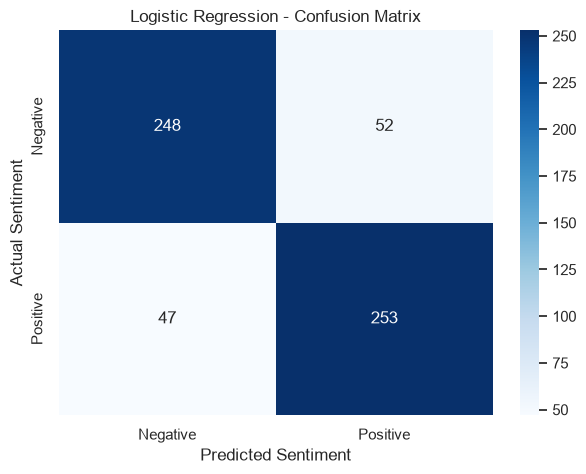

In [18]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.savefig(
    "../visualizations/confusion_matrix.png",
    bbox_inches="tight"
)

plt.show()


## VADER Sentiment Analysis

VADER (Valence Aware Dictionary and sEntiment Reasoner) is a rule-based sentiment analysis tool provided by NLTK.

It analyzes text and calculates a compound sentiment score.

Classification thresholds:
- Compound score >= 0.05: Positive
- Compound score <= -0.05: Negative
- Otherwise: Neutral


In [19]:
sia = SentimentIntensityAnalyzer()

def get_vader_sentiment(text):
    score = sia.polarity_scores(str(text))['compound']

    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

df['vader_sentiment'] = df['review'].apply(get_vader_sentiment)

print("VADER sentiment analysis completed!")
print(df['vader_sentiment'].value_counts())

VADER sentiment analysis completed!
vader_sentiment
Positive    1460
Negative     870
Neutral      670
Name: count, dtype: int64


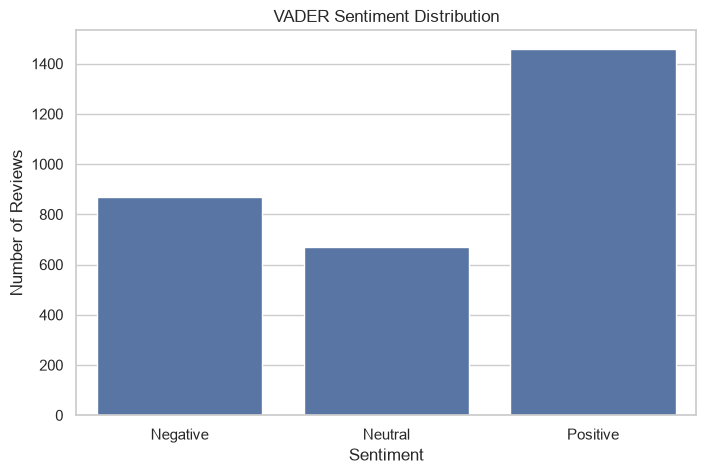

In [20]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='vader_sentiment',
    order=['Negative', 'Neutral', 'Positive']
)

plt.title("VADER Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.savefig(
    "../visualizations/vader_sentiment_distribution.png",
    bbox_inches="tight"
)

plt.show()

VADER vs Actual Sentiment:


vader_sentiment,Negative,Neutral,Positive
ml_sentiment,,,
Negative,803,436,261
Positive,67,234,1199


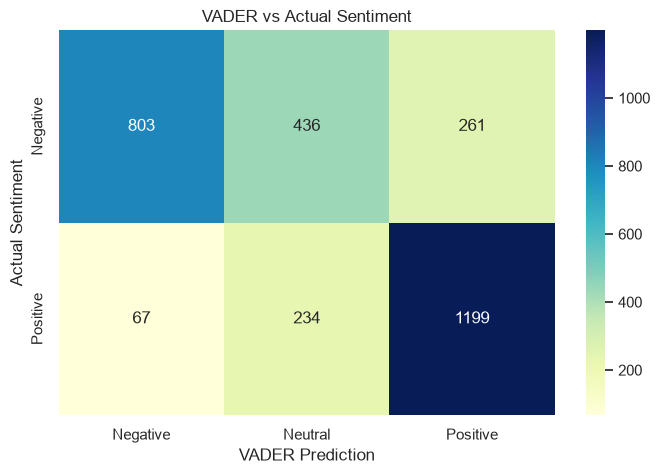

In [21]:
df['ml_sentiment'] = df['label'].map({
    0: 'Negative',
    1: 'Positive'
})

vader_comparison = pd.crosstab(
    df['ml_sentiment'],
    df['vader_sentiment']
)

print("VADER vs Actual Sentiment:")
display(vader_comparison)

plt.figure(figsize=(8, 5))

sns.heatmap(
    vader_comparison,
    annot=True,
    fmt='d',
    cmap='YlGnBu'
)

plt.title("VADER vs Actual Sentiment")
plt.xlabel("VADER Prediction")
plt.ylabel("Actual Sentiment")

plt.savefig(
    "../visualizations/vader_comparison.png",
    bbox_inches="tight"
)

plt.show()

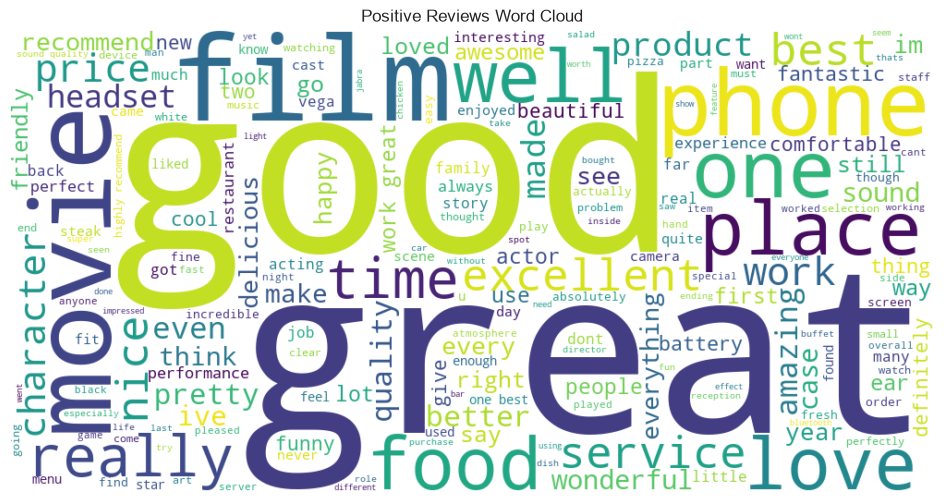

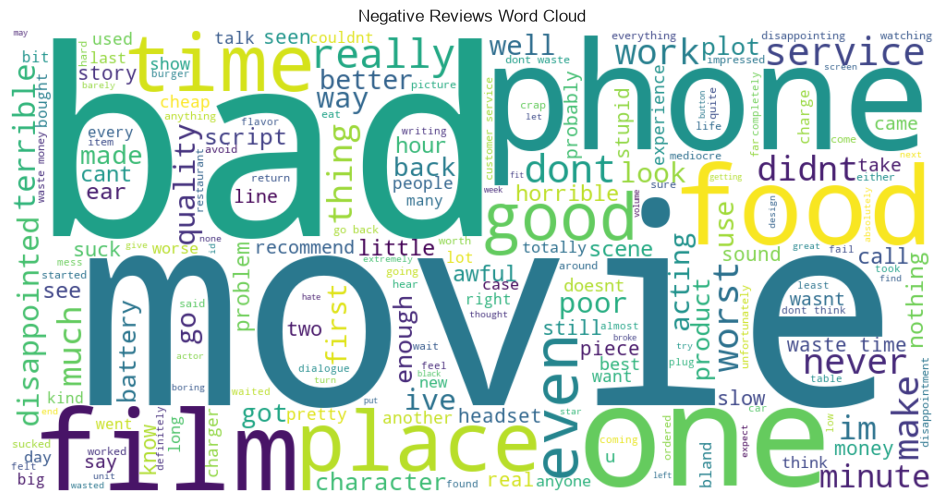

In [22]:
positive_text = ' '.join(
    df[df['label'] == 1]['cleaned_review']
)

negative_text = ' '.join(
    df[df['label'] == 0]['cleaned_review']
)

positive_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(positive_text)

negative_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(negative_text)

plt.figure(figsize=(12, 6))
plt.imshow(positive_wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Positive Reviews Word Cloud")
plt.savefig(
    "../visualizations/positive_wordcloud.png",
    bbox_inches="tight"
)
plt.show()

plt.figure(figsize=(12, 6))
plt.imshow(negative_wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Negative Reviews Word Cloud")
plt.savefig(
    "../visualizations/negative_wordcloud.png",
    bbox_inches="tight"
)
plt.show()

In [23]:
def predict_sentiment(review):
    cleaned = clean_text(review)
    vectorized = tfidf.transform([cleaned])

    prediction = model.predict(vectorized)[0]
    probability = model.predict_proba(vectorized)[0]

    sentiment = 'Positive' if prediction == 1 else 'Negative'
    confidence = max(probability) * 100

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print(f"Confidence: {confidence:.2f}%")
    print("-" * 50)


predict_sentiment("This product is amazing and I really love it!")

predict_sentiment("This is the worst product I have ever purchased.")

Review: This product is amazing and I really love it!
Predicted Sentiment: Positive
Confidence: 90.20%
--------------------------------------------------
Review: This is the worst product I have ever purchased.
Predicted Sentiment: Negative
Confidence: 79.86%
--------------------------------------------------


In [24]:
df.to_csv(
    "../dataset/sentiment_analysis_results.csv",
    index=False
)

print("Final sentiment analysis results saved successfully!")

Final sentiment analysis results saved successfully!



# Conclusion

This project successfully demonstrates sentiment analysis using Natural Language Processing and Machine Learning techniques.

### Key Achievements

- Collected and analyzed 3,000 customer reviews from Amazon, IMDb, and Yelp.
- Performed text cleaning, stopword removal, and lemmatization.
- Converted text into numerical features using TF-IDF.
- Trained a Logistic Regression classification model.
- Evaluated model performance using accuracy, classification report, and confusion matrix.
- Applied VADER for rule-based sentiment analysis.
- Generated positive and negative word clouds.
- Tested the model using custom customer reviews.

### Future Enhancements

- Experiment with advanced machine learning algorithms.
- Implement deep learning models such as LSTM and BERT.
- Build an interactive sentiment analysis web application.
- Support multiple languages.
- Analyze real-time customer feedback.

### Final Outcome

The project demonstrates how NLP and machine learning can be used to understand customer opinions and classify reviews into positive and negative sentiments.
